In [1]:
import numpy as np
import pandas as pd

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("../data/MSRCT_data.csv")


In [11]:
df.head()

,ID,group name,gender,age,EDSS_pretest,EDSS_post,EDSS diff,IGF-1_pretest (ng/ml),IGF-1_post (ng/ml),IGF-1 diff,...,Three minutes step test diff,10-metre_timed_walk_test_pretest (s),10-metre_timed_walk_test_post (s),10-metre timed walk test diff,Standing_balance_test_pretest (s),Standing_balance_test_post (s),Standing balance test diff,The_sit_&_reach_test_pretest (cm),The_sit_&_reach_test_post (cm),The sit & reach-A test diff
0,MS_001,exercise,m,52,3.0,2.5,-0.5,256.1,389.5,133.4,...,11,12.81,8.65,-4.16,55.38,86.46,31.08,4.02,6.08,2.06
1,MS_002,exercise,m,31,2.0,2.0,0.0,411.3,419.4,8.1,...,17,8.34,6.02,-2.32,79.12,95.15,16.03,5.18,9.12,3.94
2,MS_003,exercise,f,33,1.0,1.0,0.0,269.5,372.0,102.5,...,16,7.01,4.81,-2.20,70.06,89.42,19.36,6.11,8.71,2.60
3,MS_004,VR,f,39,2.0,2.0,0.0,385.4,362.5,-22.9,...,2,10.25,8.80,-1.45,64.60,66.50,1.90,5.07,5.02,-0.05
4,MS_005,VR,m,34,4.0,4.5,0.5,412.5,386.0,-26.5,...,-3,14.00,13.12,-0.88,55.42,57.03,1.61,4.71,4.80,0.09


In [12]:
exercise_df = df[df['group name'] == 'exercise']

before = exercise_df['10-metre_timed_walk_test_pretest (s)']
after = exercise_df['10-metre_timed_walk_test_post (s)']

print("Number of participants:", len(exercise_df))
print("Before training — Mean:", before.mean())
print("After training — Mean:", after.mean())

Number of participants: 19
Before training — Mean: 8.906315789473684
After training — Mean: 6.499473684210526


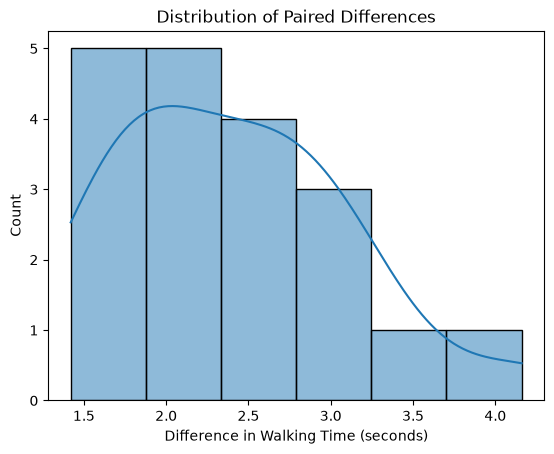

In [13]:
differences = before - after

sns.histplot(differences, kde=True)
plt.xlabel("Difference in Walking Time (seconds)")
plt.title("Distribution of Paired Differences")
plt.show()

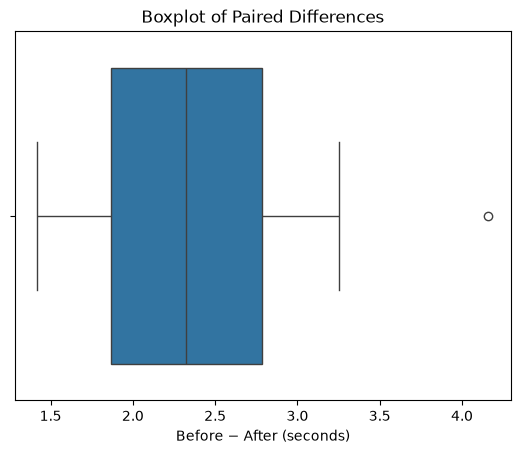

In [14]:
sns.boxplot(x=differences)
plt.title("Boxplot of Paired Differences")
plt.xlabel("Before − After (seconds)")
plt.show()

In [15]:
stats.shapiro(differences)

ShapiroResult(statistic=np.float64(0.9488464696253752), pvalue=np.float64(0.37767574162129025))

In [16]:
t_stat, p_value = stats.ttest_rel(before, after)

print("Before Mean:", before.mean())
print("After Mean:", after.mean())
print("Mean Difference:", (before - after).mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)
alpha = 0.05

if p_value <= alpha:
    print("Reject H0: Significant difference")
else:
    print("Fail to reject H0: Insufficient evidence of a significant difference")

Before Mean: 8.906315789473684
After Mean: 6.499473684210526
Mean Difference: 2.406842105263158
T-statistic: 14.90047399037602
P-value: 1.440841013599141e-11
Reject H0: Significant difference


In [17]:
# Cohen's d for paired t-test
cohens_d = differences.mean() / differences.std(ddof=1)

print("Mean difference:", differences.mean())
print("SD of differences:", differences.std(ddof=1))
print("Cohen's d:", cohens_d)

Mean difference: 2.406842105263158
SD of differences: 0.7040837436900919
Cohen's d: 3.418403175521332


In [21]:
from statsmodels.stats.power import TTestPower

power_analysis = TTestPower()
required_n = power_analysis.solve_power(
    effect_size=3.4,
    power=0.80,
    alpha=0.05,
    alternative='two-sided'
)

print(np.ceil(required_n))

3.0
